# Spectrum Analyser Background Noise Simulation

Models the background noise reading of a spectrum analyser connected to a circuit that terminates in a cold resistor, with 3 LNA stages in the chain.

## Signal chain

```
[ Cold resistor (T_cold) ] → [ Lossy circuit (T_env, S21) ] → [ LNA 1 ] → [ LNA 2 ] → [ LNA 3 ] → [ Spectrum Analyser ]
```

## Model

**Step 1 — Lossy circuit (Friis lossy line):**  
The cold load noise is attenuated by the circuit, while the lossy elements inject their own thermal noise at $T_{env}$:
$$T_{circuit\_out}(f) = T_{cold} \cdot |S_{21}(f)|^2 + T_{env} \cdot (1 - |S_{21}(f)|^2)$$

**Step 2 — LNA chain (Friis noise formula):**  
Each LNA has gain $G_i$ and noise temperature $T_{LNA,i}$ (converted from noise figure). The total system noise temperature referred to the input of LNA 1 is:
$$T_{sys}(f) = T_{circuit\_out}(f) + T_{LNA,1} + \frac{T_{LNA,2}}{G_1} + \frac{T_{LNA,3}}{G_1 G_2}$$

**Step 3 — SA input noise PSD:**
$$P_{out}(f) = 10\log_{10}\!\left(\frac{k_B \cdot T_{sys}(f)}{10^{-3}}\right) \quad [\text{dBm/Hz}]$$

## 1 · Imports

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

%matplotlib inline
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.grid': True,
    'grid.linestyle': '--',
    'grid.alpha': 0.5,
})

K_B   = 1.380649e-23  # Boltzmann constant [J/K]
T_0   = 290.0         # IEEE reference temperature for noise figure [K]
REF_W = 1e3          # 1 mW reference for dBm

## 2 · Configuration — edit here

In [ ]:
# ── S21 file ──────────────────────────────────────────────────────────────────
CSV_PATH = "C:\\Users\\nicoe\\OneDrive - Imperial College London\\Documents\\A Univeristy\\Year 4\\Masters Project\\Results\\S21 components\\preamp_S21.csv"       # Columns: frequency_hz, s21_db

COMPONENT_CSV_PATHS = [
       "component_1_s21.csv",
       "component_2_s21.csv",
       ...
   ]

# ── Temperatures ──────────────────────────────────────────────────────────────
T_COLD = 77.0                   # Cold terminal resistor temperature [K]
T_ENV  = 290.0                  # Physical temperature of the lossy circuit [K]

# ── LNA stages (in order from circuit output → SA) ───────────────────────────
# Each entry: (gain_dB, noise_figure_dB)
LNAS = [
    (22.0, 1.4),   # LNA 1  — closest to circuit
    (22.0, 1.4),   # LNA 2
    (21.0, 1.6),   # LNA 3  — closest to SA
]

# ── Integration bandwidth (None = full CSV range) ─────────────────────────────
F_MIN = 6.85e9                   # e.g. 1e6 for 1 MHz
F_MAX = 7.15e9               # e.g. 1e9 for 1 GHz

## 3 · Load S21 data

In [44]:
def load_s21_csv(filepath):
    """Load CSV and return (frequency_hz, s21_db) sorted by frequency."""
    headers_used = ['Frequency (Hz)', 'S21 (dB)']
    df = pd.read_csv(filepath, comment='!', sep=',', names=headers_used, header=0)
    df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]

    freq_col = next((c for c in df.columns if "freq" in c or c in ("f", "hz")), None)
    s21_col  = next((c for c in df.columns if "s21" in c or "gain" in c or "mag" in c), None)

    if freq_col is None or s21_col is None:
        raise ValueError(
            f"Cannot identify frequency / S21 columns.\n"
            f"Found: {list(df.columns)}\n"
            f"Expected names containing 'freq' and 's21'."
        )

    print(f"Using columns → frequency: '{freq_col}',  S21: '{s21_col}'")
    freq = df[freq_col].to_numpy(float)
    s21  = df[s21_col].to_numpy(float)
    idx  = np.argsort(freq)
    return freq[idx], s21[idx]


freq, s21_db = load_s21_csv(CSV_PATH)
print(f"Loaded {len(freq)} points: {freq[0]:.3g} Hz – {freq[-1]:.3g} Hz")
pd.DataFrame({"frequency_hz": freq, "s21_db": s21_db}).head()

Using columns → frequency: 'frequency_(hz)',  S21: 's21_(db)'
Loaded 200 points: 8.03e+07 Hz – 1.6e+10 Hz


,frequency_hz,s21_db
0,80298500.0,-0.060668
1,160297000.0,-0.157485
2,240295500.0,-0.176579
3,320294000.0,-0.260390
4,400292500.0,-0.090193


## 4 · Noise helper functions

In [46]:
def nf_to_noise_temp(nf_db, t_ref=T_0):
    """Convert noise figure [dB] to noise temperature [K]."""
    nf_linear = 10 ** (nf_db / 10)
    return t_ref * (nf_linear - 1)


def friis_lna_chain(t_input, lnas):
    """
    Apply Friis noise formula for a chain of LNA stages.

    Parameters
    ----------
    t_input : float or np.ndarray
        Noise temperature [K] at the input of LNA 1.
    lnas : list of (gain_db, nf_db) tuples
        LNA stages in order from input to output.

    Returns
    -------
    t_sys : same type as t_input
        System noise temperature [K] referred to input of LNA 1.
    t_lna_contributions : list of floats
        Noise temperature contribution of each LNA referred to LNA 1 input.
    """
    t_sys = t_input.copy() if isinstance(t_input, np.ndarray) else float(t_input)
    cumulative_gain = 1.0
    contributions = []

    for i, (gain_db, nf_db) in enumerate(lnas):
        t_lna = nf_to_noise_temp(nf_db)
        contribution = t_lna / cumulative_gain
        t_sys = t_sys + contribution
        contributions.append(float(contribution))
        cumulative_gain *= 10 ** (gain_db / 10)

    return t_sys, contributions


# Print LNA noise temperatures for reference
print("LNA noise temperatures (referred to LNA 1 input):")
print(f"  {'Stage':<8} {'Gain (dB)':<12} {'NF (dB)':<10} {'T_LNA (K)':<12} {'T_referred (K)'}")
print("  " + "-" * 58)
cumg = 1.0
for i, (g, nf) in enumerate(LNAS):
    t_lna = nf_to_noise_temp(nf)
    t_ref = t_lna / cumg
    print(f"  LNA {i+1:<4} {g:<12.1f} {nf:<10.2f} {t_lna:<12.3f} {t_ref:.3f}")
    cumg *= 10 ** (g / 10)

LNA noise temperatures (referred to LNA 1 input):
  Stage    Gain (dB)    NF (dB)    T_LNA (K)    T_referred (K)
  ----------------------------------------------------------
  LNA 1    22.0         1.40       110.311      110.311
  LNA 2    22.0         1.40       110.311      0.696
  LNA 3    21.0         1.60       129.178      0.005


## 5 · Compute system noise temperature and output PSD

In [47]:
# ── Step 1: Friis lossy circuit ───────────────────────────────────────────────
# |S21|² is the power transmission through the lossy circuit
s21_power = 10 ** (s21_db / 10)     # linear power ratio (≤ 1 for passive circuit)

# Effective noise temperature at the output of the lossy circuit
# = cold load noise that survives the loss + environmental noise injected by losses
t_circuit_out = T_COLD * s21_power + T_ENV * (1 - s21_power)

# ── Step 2: Friis LNA chain ───────────────────────────────────────────────────
# t_sys is the total system noise temperature referred to LNA 1 input
t_sys, lna_contributions = friis_lna_chain(t_circuit_out, LNAS)

# ── Step 3: Output noise PSD at SA input ──────────────────────────────────────
R = 50.0  # System impedance [Ohms]

noise_psd_W_hz   = K_B * t_sys
noise_psd_dbm_hz = 10 * np.log10(noise_psd_W_hz / REF_W)
noise_nv_sqrtHz = np.sqrt(noise_psd_W_hz * R) * 1e9

# Reference levels
kt_cold_dbm_hz = 10 * np.log10(K_B * T_COLD / REF_W)
kt_cold_nv_sqrtHz = np.sqrt(K_B * T_COLD * R) * 1e9

kt_env_dbm_hz  = 10 * np.log10(K_B * T_ENV  / REF_W)
kt_env_nv_sqrtHz = np.sqrt(K_B * T_ENV * R) * 1e9


print(f"kT_cold floor  (T={T_COLD} K)   : {kt_cold_dbm_hz:.2f} dBm/Hz")
print(f"kT_env  floor  (T={T_ENV} K) : {kt_env_dbm_hz:.2f} dBm/Hz")
print()
print(f"LNA noise contributions referred to LNA 1 input:")
for i, tc in enumerate(lna_contributions):
    print(f"  LNA {i+1}: {tc:.3f} K  ({10*np.log10(K_B*tc/REF_W):.2f} dBm/Hz)")
print()
print(f"System noise PSD at SA (peak) : {noise_psd_dbm_hz.max():.2f} dBm/Hz")
print(f"System noise PSD at SA (min)  : {noise_psd_dbm_hz.min():.2f} dBm/Hz")

kT_cold floor  (T=77.0 K)   : -239.73 dBm/Hz
kT_env  floor  (T=290.0 K) : -233.98 dBm/Hz

LNA noise contributions referred to LNA 1 input:
  LNA 1: 110.311 K  (-238.17 dBm/Hz)
  LNA 2: 0.696 K  (-260.17 dBm/Hz)
  LNA 3: 0.005 K  (-281.49 dBm/Hz)

System noise PSD at SA (peak) : -232.83 dBm/Hz
System noise PSD at SA (min)  : -235.79 dBm/Hz


## 6 · Integrate noise power over bandwidth

In [48]:
mask = np.ones(len(freq), dtype=bool)
if F_MIN is not None:
    mask &= freq >= F_MIN
if F_MAX is not None:
    mask &= freq <= F_MAX

integrated_W   = trapezoid(noise_psd_W_hz[mask], freq[mask])
integrated_dbm = 10 * np.log10(integrated_W / REF_W)

print(f"Integration range  : {freq[mask][0]:.3g} Hz – {freq[mask][-1]:.3g} Hz  ({mask.sum()} points)")
print(f"Integrated noise   : {integrated_dbm:.4f} dBm")

Integration range  : 6.88e+09 Hz – 7.12e+09 Hz  (4 points)
Integrated noise   : -150.3987 dBm


## 7 · Plot

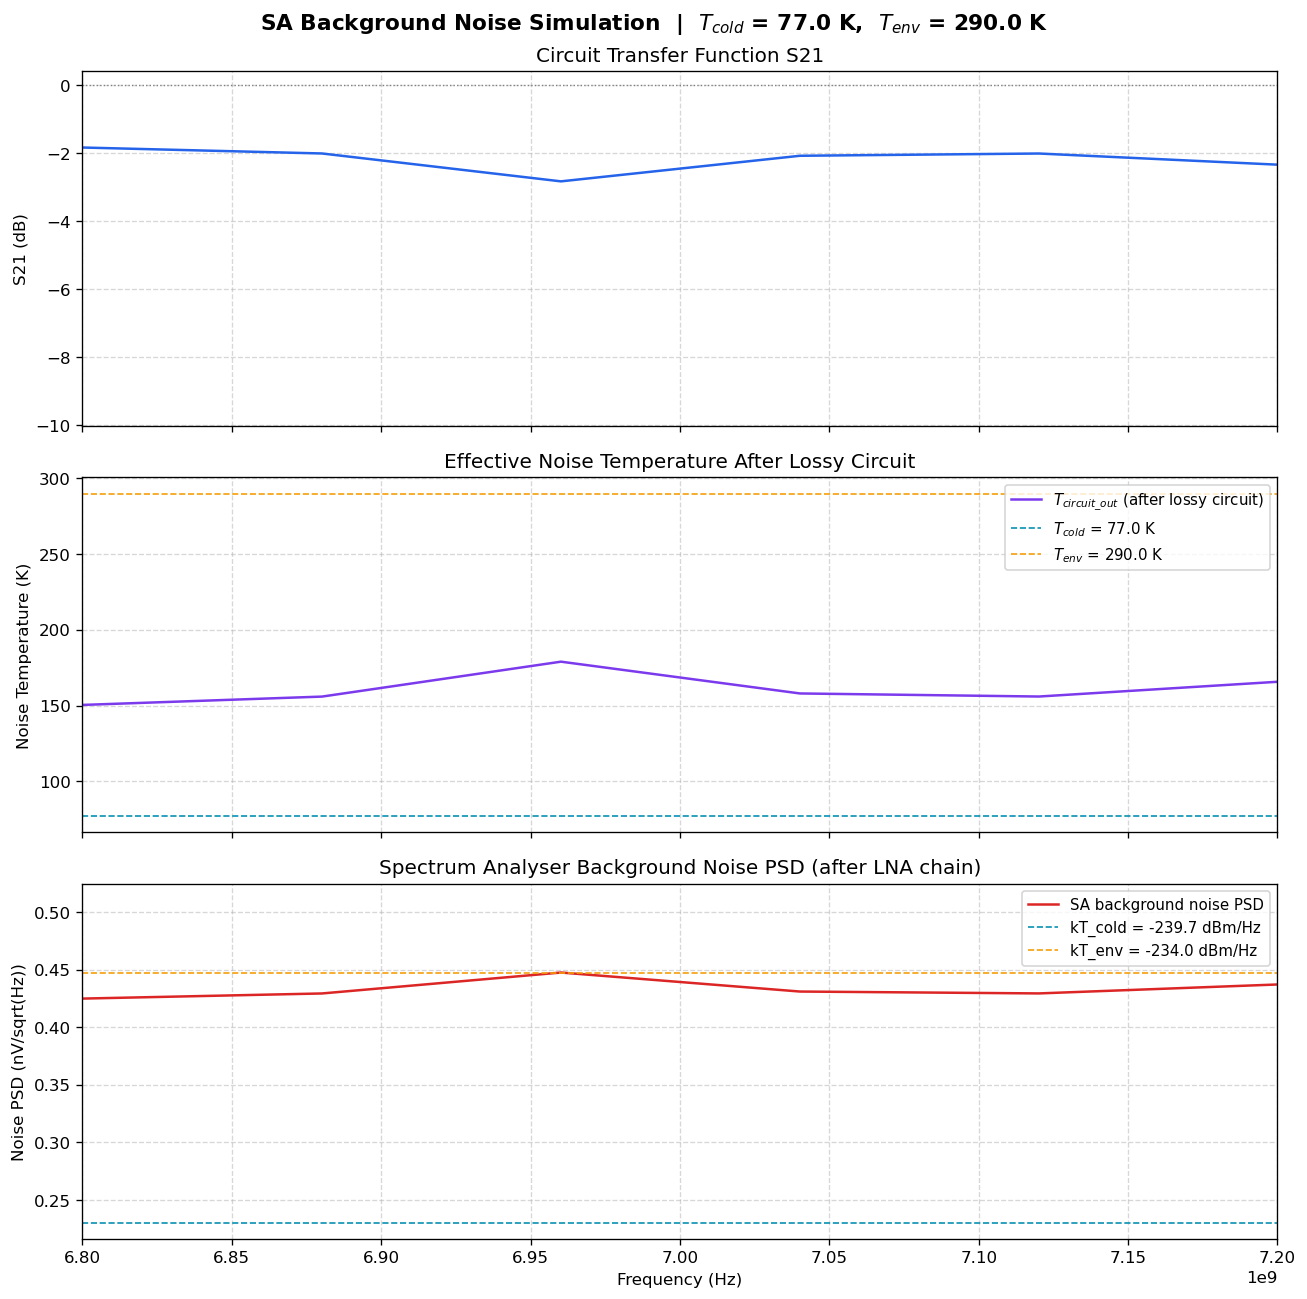

In [52]:
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
fig.suptitle(
    f"SA Background Noise Simulation  |  "
    f"$T_{{cold}}$ = {T_COLD} K,  $T_{{env}}$ = {T_ENV} K",
    fontsize=13, fontweight="bold",
)

# ── S21 ───────────────────────────────────────────────────────────────────────
axes[0].plot(freq, s21_db, color="#2563eb", linewidth=1.5)
axes[0].axhline(0, color="gray", linewidth=0.8, linestyle=":")
axes[0].set_ylabel("S21 (dB)")
axes[0].set_title("Circuit Transfer Function S21")

# ── Effective noise temperature at circuit output ─────────────────────────────
axes[1].plot(freq, t_circuit_out, color="#7c3aed", linewidth=1.5,
             label="$T_{circuit\_out}$ (after lossy circuit)")
axes[1].axhline(T_COLD, color="#0891b2", linewidth=1.0, linestyle="--",
                label=f"$T_{{cold}}$ = {T_COLD} K")
axes[1].axhline(T_ENV,  color="#f59e0b", linewidth=1.0, linestyle="--",
                label=f"$T_{{env}}$ = {T_ENV} K")
axes[1].set_ylabel("Noise Temperature (K)")
axes[1].set_title("Effective Noise Temperature After Lossy Circuit")
axes[1].legend(fontsize=9)

# ── SA output noise PSD ───────────────────────────────────────────────────────
axes[2].plot(freq, noise_nv_sqrtHz, color="#dc2626", linewidth=1.5,
             label="SA background noise PSD")
axes[2].axhline(kt_cold_nv_sqrtHz, color="#0891b2", linewidth=1.0, linestyle="--",
                label=f"kT_cold = {kt_cold_dbm_hz:.1f} dBm/Hz")
axes[2].axhline(kt_env_nv_sqrtHz,  color="#f59e0b", linewidth=1.0, linestyle="--",
                label=f"kT_env = {kt_env_dbm_hz:.1f} dBm/Hz")
# axes[2].fill_between(freq[mask], noise_psd_dbm_hz[mask], alpha=0.15,
#                      color="#dc2626",
#                      label=f"Integrated = {integrated_dbm:.2f} dBm")
axes[2].set_ylabel("Noise PSD (nV/sqrt(Hz))")
axes[2].set_xlabel("Frequency (Hz)")
axes[2].set_title("Spectrum Analyser Background Noise PSD (after LNA chain)")
axes[2].legend(fontsize=9)

for ax in axes:
    ax.set_xlim(6.8e9,7.2e9)

plt.tight_layout()
# plt.savefig("sa_noise_simulation_plot.png", dpi=150)
plt.show()

## 8 · Noise budget breakdown

In [ ]:
# Decompose what fraction of noise at SA comes from each source
# All referred to LNA 1 input, averaged over frequency

t_cold_surviving  = np.mean(T_COLD * s21_power)           # cold load through circuit
t_env_injected    = np.mean(T_ENV  * (1 - s21_power))     # environment via circuit losses
t_lna1            = lna_contributions[0]
t_lna2            = lna_contributions[1]
t_lna3            = lna_contributions[2]
t_total           = t_cold_surviving + t_env_injected + t_lna1 + t_lna2 + t_lna3

budget = {
    "Cold load (through circuit)": t_cold_surviving,
    "Environment (circuit losses)": t_env_injected,
    "LNA 1": t_lna1,
    "LNA 2": t_lna2,
    "LNA 3": t_lna3,
}

print(f"{'Source':<30} {'T_noise (K)':>12} {'Fraction (%)':>14}")
print("-" * 58)
for label, t in budget.items():
    print(f"{label:<30} {t:>12.3f} {100*t/t_total:>13.1f}%")
print("-" * 58)
print(f"{'Total (mean over frequency)':<30} {t_total:>12.3f} {'100.0%':>14}")

# Pie chart
fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#0891b2", "#f59e0b", "#16a34a", "#7c3aed", "#dc2626"]
wedges, texts, autotexts = ax.pie(
    list(budget.values()),
    labels=list(budget.keys()),
    autopct="%1.1f%%",
    colors=colors,
    startangle=140,
    pctdistance=0.78,
)
for at in autotexts:
    at.set_fontsize(9)
ax.set_title(
    f"Noise Budget (mean over frequency)\nTotal = {t_total:.2f} K",
    fontsize=11, fontweight="bold",
)
plt.tight_layout()
plt.savefig("sa_noise_budget.png", dpi=150)
plt.show()

## 9 · Export results

In [ ]:
results = pd.DataFrame({
    "frequency_hz":              freq,
    "s21_db":                    s21_db,
    "s21_linear_power":          s21_power,
    "t_circuit_out_K":           t_circuit_out,
    "t_sys_K":                   t_sys,
    "noise_psd_dbm_hz":          noise_psd_dbm_hz,
    "noise_psd_W_hz":            noise_psd_W_hz,
})

results.to_csv("sa_noise_simulation_output.csv", index=False)
print("Saved → sa_noise_simulation_output.csv")
results.head(10)